# 00 — Complete MVTec AD dataset EDA

Research foundation for normal-only industrial anomaly detection in PyTorch.
This notebook is the chronological scientific narrative, together with the
[research protocol](../docs/research_protocol.md). No anomaly detection model is
fitted here. Milestone 1 verified only a missing-data path; Milestone 2 validates
the user-provided original dataset in this project's data directory.

**Execution contract:** run top to bottom with the isolated project `.venv` and
its `mvtec-research` Jupyter kernel. The dataset root is discovered under `data/`;
no downloading, reorganization or source-image modification occurs. Compact
numeric outputs and aggregate plots are published. Panels containing dataset
pixels remain in the full local `outputs/eda/00_dataset_eda.executed.ipynb`.

## 1. Introduction and questions

We compare normal-only image detection and defect localization across six
planned model families. First ask: is the complete dataset intact, what spatial
detail might resizing lose, and can fixed normal partitions support defensible
calibration? The primary input resolution is preregistered at 256×256, not selected
by test performance. Configuration and data provenance must remain traceable.

In [1]:
from pathlib import Path
import sys, json, hashlib
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
assert (ROOT / "pyproject.toml").is_file(), "Run from repository or notebooks/"
sys.path.insert(0, str(ROOT / "src"))
sys.path.insert(0, str(ROOT / "scripts"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display
from anomaly_detection.data import (CATEGORIES, TEXTURES, project_data_root,
                                    discover, inventory, partitions)
from anomaly_detection.tracking import config_hash
config = json.loads((ROOT / "configs/eda.json").read_text())
print(json.dumps(config, indent=2))
print("Configuration SHA256:", config_hash(config))

{
  "dataset_root": "auto",
  "seed": 2026,
  "partition_fractions": {
    "fit": 0.7,
    "development": 0.15,
    "calibration": 0.15
  },
  "resize_candidate": [
    256,
    256
  ],
  "target_image_fpr": 0.05,
  "test_usage": "descriptive EDA only; no selection or calibration"
}
Configuration SHA256: 079be9ddc2e4a6b18a2485c7f8dd4685a0e8571335b0bd690d788c5db0497cab


The displayed configuration is the exact one used below. EDA performs no
hyperparameter selection, model fitting, threshold optimization or accuracy claim.

## 2. Origin and organization

The [official MVTec AD page](https://www.mvtec.com/research-teaching/datasets/mvtec-ad)
describes defect-free training images, normal and defective test images, and
pixel annotations for defects across 15 categories. Cite Bergmann et al. (CVPR
2019) and the extended IJCV paper. Data is CC BY-NC-SA 4.0. Follow the official
download form; see [acquisition instructions](../docs/dataset.md).
Expected hierarchy: `<category>/train/good`, `test/<defect or good>`, and
`ground_truth/<defect>/*_mask.png`. No other project is a data source.

In [2]:
DATA = project_data_root(ROOT, config["dataset_root"])
OUT = ROOT / "outputs/eda"
OUT.mkdir(parents=True, exist_ok=True)
print("Automatically discovered dataset root:", DATA.relative_to(ROOT))
print("Directory exists:", DATA.is_dir())
import shutil
disk = shutil.disk_usage(ROOT)
print(f"Available disk space: {disk.free / 2**30:.2f} GiB")

Automatically discovered dataset root: data\mvtec_ad
Directory exists: True
Available disk space: 550.67 GiB


A directory alone does not establish completeness. Discovery and full decoding
below must succeed before reporting measured dataset statistics.

## 3. Environment and GPU inspection

Inspect actual imports, CUDA build/runtime availability and driver-visible
hardware. A driver's CUDA version is not proof that PyTorch has CUDA support.

In [3]:
from environment import inspect
from verify_cuda import verify_gpu
environment = inspect()
cuda_check = verify_gpu()
assert cuda_check["isolated"], "Use the project's isolated .venv"
assert Path(sys.prefix).resolve() == (ROOT / ".venv").resolve()
display(environment)
display(cuda_check)
(OUT / "environment.json").write_text(json.dumps(environment, indent=2) + "\n")
(ROOT / "reports/environment.json").write_text(json.dumps(environment, indent=2) + "\n")
(ROOT / "reports/cuda_verification.json").write_text(json.dumps(cuda_check, indent=2) + "\n")

{'recorded_at_utc': '2026-11-12T05:22:22.786578+00:00',
 'python': '3.12.10',
 'platform': 'Windows-11-10.0.26300-SP0',
 'packages': {'torch': '2.11.0+cu128',
  'torchvision': '0.26.0+cu128',
  'numpy': '2.2.6',
  'pillow': '11.2.1',
  'pandas': '2.2.3',
  'matplotlib': '3.10.3',
  'scikit-learn': '1.6.1',
  'nbformat': '5.10.4',
  'nbclient': '0.10.2',
  'ipykernel': '6.29.5',
  'jupyterlab': '4.4.3',
  'pytest': '8.3.5'},
 'torch_version': '2.11.0+cu128',
 'torchvision_version': '0.26.0+cu128',
 'cuda_build': '12.8',
 'cuda_available': True,
 'gpu': 'NVIDIA GeForce RTX 4060 Laptop GPU',
 'gpu_memory_bytes': 8585216000,
 'cuda_smoke': 4.0,
 'nvidia_smi': 'NVIDIA GeForce RTX 4060 Laptop GPU, 610.91, 8188 MiB'}

{'verified_at_utc': '2026-11-12T05:22:29.724266+00:00',
 'python': '3.12.10',
 'interpreter': '.venv\\Scripts\\python.exe',
 'isolated': True,
 'torch': '2.11.0+cu128',
 'torchvision': '0.26.0+cu128',
 'cuda_runtime': '12.8',
 'cudnn': 91900,
 'cuda_available': True,
 'device': 'NVIDIA GeForce RTX 4060 Laptop GPU',
 'device_memory_bytes': 8585216000,
 'matrix_max_absolute_error': 0.00042724609375,
 'matrix_multiply': 'passed',
 'cnn_forward_backward': 'passed; synthetic tensors, no optimizer or weight updates',
 'torchvision_cuda_nms': 'passed',
 'peak_allocated_bytes': 10416128,
 'peak_reserved_bytes': 25165824,
 'scope': 'plumbing smoke check; not model feasibility or benchmark measurement'}

724

The checks above run inside the notebook's own kernel: CUDA matrix multiplication
is checked against the CPU result, a tiny randomly initialized CNN completes
forward/backward passes on synthetic tensors, and torchvision's CUDA NMS runs.
There are no optimizer steps, dataset-based fitting or downloaded model weights.
Peak memory describes this smoke check only, not future model requirements.

## 4. Discovery and integrity checks

Only the configured project-local root is allowed. Require all categories,
decode every image, verify mask shape/binary values and pairing, hash image files,
and reject duplicate content before normal partitioning. Partial data is blocked.
Large corrupt-image exceptions deliberately stop execution for investigation.

In [4]:
found = discover(DATA)
missing = sorted(set(CATEGORIES) - set(found))
assert not missing, f"Incomplete dataset: {missing}"
READY = True
frame = inventory(DATA, progress=lambda category: print("Validating", category, flush=True))
split_manifest = partitions(frame, seed=config["seed"])
frame.to_csv(OUT / "inventory.csv", index=False, lineterminator="\n")
split_manifest.to_csv(OUT / "partitions.csv", index=False, lineterminator="\n")
print("Decoded images:", len(frame))
print("Decoded and paired defect masks:", int(frame["mask"].notna().sum()))
print("Exact duplicate images:", int(frame.sha256.duplicated().sum()))

Validating bottle


Validating cable


Validating capsule


Validating carpet


Validating grid


Validating hazelnut


... (6 outputs left out)

Validating transistor


Validating wood


Validating zipper


Decoded images: 5354
Decoded and paired defect masks: 1258
Exact duplicate images: 0


Every image and defective-test mask must pass verification and full decoding.
This execution stops on missing categories, corrupt files, mask inconsistencies,
linked entries or exact image duplicates; it never silently drops data. The
inventory includes original dimensions, image and mask SHA256 hashes. These
self-computed identities do not authenticate an unavailable original archive.

## 5. All category names

The expected coverage is fixed in advance. Texture/object membership describes
the benchmark taxonomy and is separate from locally measured counts.

In [5]:
category_table = pd.DataFrame({"category": CATEGORIES,
    "kind": ["texture" if c in TEXTURES else "object" for c in CATEGORIES],
    "discovered": [c in found for c in CATEGORIES]})
display(category_table)

,category,kind,discovered
0,bottle,object,True
1,cable,object,True
2,capsule,object,True
3,carpet,texture,True
4,grid,texture,True
5,hazelnut,object,True
6,leather,texture,True
7,metal_nut,object,True
8,pill,object,True
9,screw,object,True


All 15 categories are present: five textures and ten objects. Coverage is complete,
but category sample sizes differ. The final comparison must retain every category
and give each equal weight in the primary macro average.

## 6. Image counts by category and split

Count decoded files, separating train normals, test normals and test defects.
These counts are measured only after complete integrity checks.

,train_normal,test_normal,test_defective,total
category,,,,
bottle,209,20,63,292
cable,224,58,92,374
capsule,219,23,109,351
carpet,280,28,89,397
grid,264,21,57,342
hazelnut,391,40,70,501
leather,245,32,92,369
metal_nut,220,22,93,335
pill,267,26,141,434


Totals: {'train_normal': 3629, 'test_normal': 467, 'test_defective': 1258, 'total': 5354}


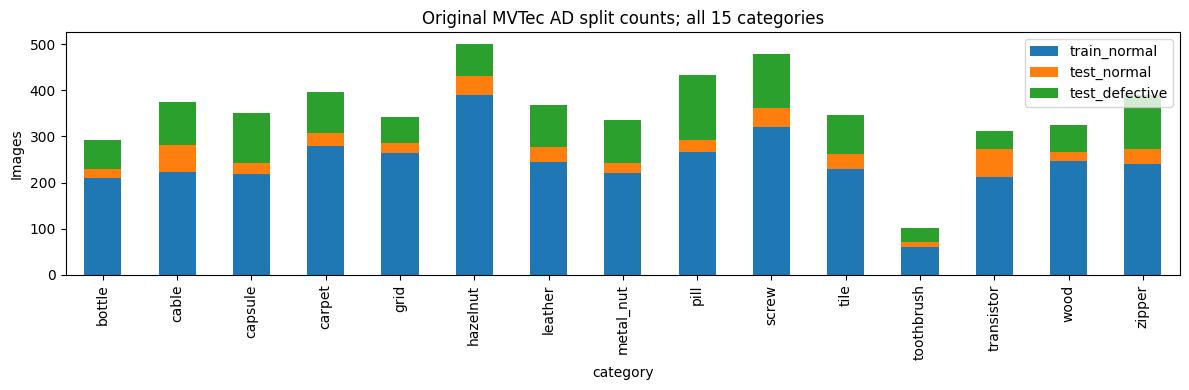

In [6]:
counts = pd.DataFrame(index=pd.Index(CATEGORIES, name="category"))
counts["train_normal"] = frame[frame.split == "train"].groupby("category").size()
counts["test_normal"] = frame[(frame.split == "test") & ~frame.anomalous].groupby("category").size()
counts["test_defective"] = frame[(frame.split == "test") & frame.anomalous].groupby("category").size()
counts["total"] = counts.sum(axis=1)
display(counts)
print("Totals:", counts.sum().to_dict())
counts.to_csv(ROOT / "reports/category_counts.csv", lineterminator="\n")
counts[["train_normal", "test_normal", "test_defective"]].plot.bar(stacked=True, figsize=(12,4), ylabel="Images")
plt.title("Original MVTec AD split counts; all 15 categories")
plt.tight_layout(); plt.savefig(OUT / "category_counts.png", dpi=110); plt.show()

**Observed:** 5,354 images comprise 3,629 normal training images,
467 normal test images and 1,258 defective test images.
Training counts range from 60 (toothbrush)
to 391 (hazelnut). Normal/defective test
balance also varies, so accuracy and pooled-image summaries alone would be
misleading. Preserve per-category AP, recall/FPR and equal-weight macro metrics.

## 7. Normal and defective samples

Show one deterministic normal training image and one defective test image per
category. These are descriptive examples; do not use their appearance to tune
models. Test exposure must be disclosed in subsequent reports.

In [7]:
if READY:
    fig, axes = plt.subplots(5, 6, figsize=(13, 11))
    for i, category in enumerate(CATEGORIES):
        subset = frame[frame.category == category]
        examples = [subset[subset.split == "train"].iloc[0],
                    subset[(subset.split == "test") & subset.anomalous].iloc[0]]
        for j, row in enumerate(examples):
            ax = axes[i // 3, (i % 3) * 2 + j]
            with Image.open(DATA / row.path) as image:
                ax.imshow(image.convert("RGB"))
            ax.set_title(f"{category} / {row.defect}", fontsize=8); ax.axis("off")
    plt.tight_layout(); plt.savefig(OUT / "all_category_samples.png", dpi=110); plt.show()
else:
    print("SKIPPED: no sample images.")

One deterministic normal/defective pair per category is displayed in the full
local executed notebook and `outputs/eda/all_category_samples.png`. This panel
contains licensed dataset pixels and is deliberately omitted from the published
copy. These selected examples do not establish severity, prevalence or model
performance; viewing test labels here is recorded as descriptive exposure.

## 8. Defect-type distributions

Enumerate actual test defect directories and counts. Defect frequency differs
from pixel area and does not justify supervised training under this protocol.

In [8]:
if READY:
    defects = frame[(frame.split == "test") & frame.anomalous].groupby(["category", "defect"]).size().rename("images")
    display(defects.to_frame())
    defects.to_csv(OUT / "defect_types.csv")
else:
    print("SKIPPED: no verified defect-type counts.")

images
category defect                 
bottle   broken_large         20
         broken_small         22
         contamination        21
cable    bent_wire            13
         cable_swap           12
...                          ...
zipper   fabric_border        17
         fabric_interior      16
         rough                17
         split_teeth          18
         squeezed_teeth       16

[73 rows x 1 columns]

**Observed:** 73 category-specific defect types are represented.
Cable has 8 types while toothbrush has 1.
These are evaluation annotations, not supervised training targets. Count imbalance
does not authorize choosing a model or threshold to favor common test defects.

The complete distribution, including rows abbreviated by the notebook display,
is retained in [published defect counts](../reports/category_defect_counts.csv).

## 9. Dimensions, channels and formats

Measure native geometry and image encodings before transforming them. Original
channels are recorded even though the proposed shared transform converts to RGB.

In [9]:
if READY:
    display(frame.groupby("category")[["width", "height", "channels"]].agg(["min", "max"]))
    display(frame.groupby(["mode", "format"]).size().rename("images").to_frame())
else:
    print("SKIPPED: dimensions/channels/formats unavailable.")

width       height       channels    
             min   max    min   max      min max
category                                        
bottle       900   900    900   900        3   3
cable       1024  1024   1024  1024        3   3
capsule     1000  1000   1000  1000        3   3
carpet      1024  1024   1024  1024        3   3
grid        1024  1024   1024  1024        1   1
hazelnut    1024  1024   1024  1024        3   3
leather     1024  1024   1024  1024        3   3
metal_nut    700   700    700   700        3   3
pill         800   800    800   800        3   3
screw       1024  1024   1024  1024        1   1
tile         840   840    840   840        3   3
toothbrush  1024  1024   1024  1024        3   3
transistor  1024  1024   1024  1024        3   3
wood        1024  1024   1024  1024        3   3
zipper      1024  1024   1024  1024        1   1

,,images
mode,format,
L,PNG,1213
RGB,PNG,4141


**Observed:** all files decode as PNG. Native images are square, with widths/heights
from 700 to 1024 pixels. Grid, screw and zipper
contain 1,213 single-channel grayscale images; other categories
are RGB. RGB conversion replicates grayscale channels and adds no color information.
Whole-image square resizing introduces no aspect-ratio distortion for these originals.

## 10. Mask availability

Every defective test image must have a nonempty, binary, native-resolution mask.
Normal images have no annotation file; zero masks are only their semantic normal
evaluation target, not generated defect labels.

In [10]:
if READY:
    masks = frame.groupby(["category", "anomalous"]).agg(images=("path", "size"), masks=("mask", "count"))
    display(masks)
    assert frame.loc[frame.anomalous, "mask"].notna().all()
    assert frame.loc[~frame.anomalous, "mask"].isna().all()
else:
    print("SKIPPED: no verified image/mask pairs.")

images  masks
category   anomalous               
bottle     False         229      0
           True           63     63
cable      False         282      0
           True           92     92
capsule    False         242      0
           True          109    109
carpet     False         308      0
           True           89     89
grid       False         285      0
           True           57     57
hazelnut   False         431      0
           True           70     70
leather    False         277      0
           True           92     92
metal_nut  False         242      0
           True           93     93
pill       False         293      0
           True          141    141
screw      False         361      0
           True          119    119
tile       False         263      0
           True           84     84
toothbrush False          72      0
           True           30     30
transistor False         273      0
           True           40     40
wood       False         266      0
           True           60     60
zipper     False         272      0
           True          119    119

**Observed:** all 1,258 defective test images have a
readable, nonempty binary 0/255 mask with matching native dimensions. No missing
or orphan masks passed validation. Normal images have no annotation files, as
expected; generated zero evaluation masks must never be represented as synthetic
defect annotations. Official masks remain outside fitting and calibration.

## 11. Image and mask comparisons

Overlay one defective example per category at native geometry. Red indicates
official annotated pixels; the image itself is not transformed before overlay.

In [11]:
if READY:
    fig, axes = plt.subplots(3, 5, figsize=(13, 8))
    for ax, category in zip(axes.flat, CATEGORIES):
        row = frame[(frame.category == category) & frame.anomalous].iloc[0]
        with Image.open(DATA / row.path) as image:
            ax.imshow(image.convert("RGB"))
        with Image.open(DATA / row["mask"]) as mask:
            foreground = np.asarray(mask) > 0
        ax.imshow(np.ma.masked_where(~foreground, foreground), cmap="Reds", alpha=.55, vmin=0, vmax=1)
        ax.set_title(category); ax.axis("off")
    plt.tight_layout(); plt.savefig(OUT / "all_category_mask_overlays.png", dpi=110); plt.show()
else:
    print("SKIPPED: no annotated examples.")

The full local notebook and `outputs/eda/all_category_mask_overlays.png` retain
the 15 category overlays for direct image/mask alignment inspection. Dataset
pixels are omitted from the published notebook, while mask availability and
integrity tables remain visible. No annotation is used for fitting or calibration.

## 12. Pixel intensities and image statistics

Summarize per-image RGB [0,1] intensity mean and population standard deviation
using official training normals only. These descriptive statistics are not fitted
normalization parameters; later normalization may use fit normals only.

mean                           std                    
                mean       min       max      mean       min       max
category                                                              
bottle      0.538350  0.527130  0.550581  0.361229  0.354692  0.366417
cable       0.402317  0.366105  0.439437  0.212743  0.180493  0.236412
capsule     0.672534  0.628631  0.736820  0.252744  0.236742  0.277373
carpet      0.356352  0.337213  0.386289  0.137452  0.125651  0.159313
grid        0.447762  0.375441  0.534536  0.156464  0.090651  0.227400
hazelnut    0.196083  0.151232  0.231813  0.111340  0.039054  0.181748
leather     0.290937  0.265028  0.345467  0.083753  0.074925  0.105132
metal_nut   0.229671  0.200611  0.272628  0.164095  0.139035  0.210740
pill        0.310261  0.289477  0.320784  0.298386  0.289832  0.314419
screw       0.722249  0.667656  0.783674  0.131755  0.114050  0.151036
tile        0.458723  0.378730  0.546501  0.124162  0.100231  0.153673
toothbrush  0.192517  0.170981  0.207492  0.213275  0.198300  0.227427
transistor  0.301403  0.273767  0.339877  0.170998  0.153465  0.188454
wood        0.498732  0.424821  0.578607  0.145615  0.122969  0.165276
zipper      0.401111  0.372021  0.425917  0.322942  0.308588  0.340506

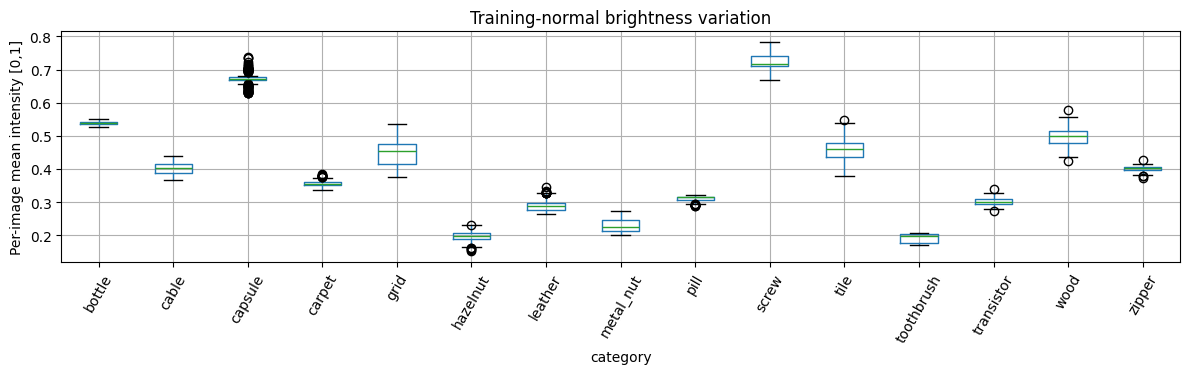

In [12]:
if READY:
    train = frame[frame.split == "train"]
    display(train.groupby("category")[["mean", "std"]].agg(["mean", "min", "max"]))
    train.boxplot(column="mean", by="category", figsize=(12, 4), rot=60)
    plt.ylabel("Per-image mean intensity [0,1]"); plt.suptitle("")
    plt.title("Training-normal brightness variation"); plt.tight_layout(); plt.savefig(OUT / "training_intensity.png", dpi=110); plt.show()
else:
    print("SKIPPED: no observed intensity statistics.")

**Observed:** category means of per-image training-normal RGB intensity range
from toothbrush (0.193) to screw (0.722) on [0,1].
The boxplot also shows within-category brightness variation. A single dataset-wide
mean would hide this structure. Keep registered preprocessing consistent, and if
normalization is learned, estimate it from fit normals only. These descriptive
statistics establish neither anomaly separability nor test-set distribution shift.

## 13. Textures versus objects

Five texture categories have repeated surface structure; ten object categories
include shape and component arrangement. Compare measured native geometry and
counts by this predefined grouping without treating categories as replicates.

In [13]:
if READY:
    grouped = frame.assign(kind=frame.category.map(lambda c: "texture" if c in TEXTURES else "object"))
    display(grouped.groupby("kind").agg(images=("path", "size"), categories=("category", "nunique"),
        median_width=("width", "median"), median_height=("height", "median")))
else:
    print("Known taxonomy: 5 texture, 10 object categories; observed summaries unavailable.")

,images,categories,median_width,median_height
kind,,,,
object,3573,10,1024.0,1024.0
texture,1781,5,1024.0,1024.0


**Observed:** five texture categories contribute 1,781 images;
ten object categories contribute 3,573. All are square, but
object native resolutions span 700–1024 pixels and texture resolutions 840–1024.
These group totals have unequal category coverage; subgroup comparisons are
supplementary to all-category macro reporting. No architectural advantage follows
from this descriptive grouping alone.

## 14. Input resolution and resizing

Quantify scale factors for the preregistered 256×256 starting resolution. Whole
image resizing can distort aspect ratios and remove tiny defects. These geometry
calculations do not select a resolution by test-mask performance.

In [14]:
if READY:
    geometry = frame[frame.split == "train"].copy()
    geometry["width_scale"] = config["resize_candidate"][0] / geometry.width
    geometry["height_scale"] = config["resize_candidate"][1] / geometry.height
    display(geometry.groupby("category")[["width_scale", "height_scale"]].agg(["min", "max"]))
else:
    print("Proposed 256x256 only; native scale factors cannot be measured.")

width_scale           height_scale          
                   min       max          min       max
category                                               
bottle        0.284444  0.284444     0.284444  0.284444
cable         0.250000  0.250000     0.250000  0.250000
capsule       0.256000  0.256000     0.256000  0.256000
carpet        0.250000  0.250000     0.250000  0.250000
grid          0.250000  0.250000     0.250000  0.250000
hazelnut      0.250000  0.250000     0.250000  0.250000
leather       0.250000  0.250000     0.250000  0.250000
metal_nut     0.365714  0.365714     0.365714  0.365714
pill          0.320000  0.320000     0.320000  0.320000
screw         0.250000  0.250000     0.250000  0.250000
tile          0.304762  0.304762     0.304762  0.304762
toothbrush    0.250000  0.250000     0.250000  0.250000
transistor    0.250000  0.250000     0.250000  0.250000
wood          0.250000  0.250000     0.250000  0.250000
zipper        0.250000  0.250000     0.250000  0.250000

**Observed:** resizing to 256×256 uses linear scale factors between 0.250 and
0.366, reducing native pixel counts by roughly 7.5–16×. Square originals retain
their aspect ratio, but small spatial details can be lost. Retain the preregistered
256×256 starting point; do not choose a better-performing resolution from official
test masks. Images use bilinear antialiasing, binary masks nearest neighbor, and
continuous predicted maps return to native resolution for evaluation.

## 15. Fit, development, calibration and test partitions

Freeze seed-2026 normal-only partitions: floor(15%) development, floor(15%)
calibration, remainder fitting per category. All official test files stay test.
The manifest stores relative paths and image hashes and is retained locally.

In [15]:
from anomaly_detection.data import sha256
display(split_manifest.groupby(["category", "partition"]).size().unstack(fill_value=0))
frozen_dir = ROOT / "reports/partitions"
frozen_dir.mkdir(parents=True, exist_ok=True)
manifest_identities = {}
for part in ("fit", "development", "calibration", "test"):
    selected = split_manifest[split_manifest.partition == part].merge(
        frame[["path", "mask", "mask_sha256"]], on="path", validate="one_to_one")
    text = selected.to_csv(index=False, lineterminator="\n")
    target = frozen_dir / f"seed2026-{part}.csv"
    if target.exists():
        assert target.read_text(encoding="utf-8") == text, "Frozen partition identity changed"
    else:
        target.write_text(text, encoding="utf-8", newline="")
    manifest_identities[part] = {"path": target.relative_to(ROOT).as_posix(),
                                "sha256": sha256(target), "images": len(selected)}
display(manifest_identities)
manifest_sha = sha256(OUT / "partitions.csv")

partition,calibration,development,fit,test
category,,,,
bottle,31,31,147,83
cable,33,33,158,150
capsule,32,32,155,132
carpet,42,42,196,117
grid,39,39,186,78
hazelnut,58,58,275,110
leather,36,36,173,124
metal_nut,33,33,154,115
pill,40,40,187,167


{'fit': {'path': 'reports/partitions/seed2026-fit.csv',
  'sha256': 'f0549001ec7bbf124b67cb3979d2af64f593a2b5c9f420838f539938b4ade912',
  'images': 2551},
 'development': {'path': 'reports/partitions/seed2026-development.csv',
  'sha256': 'e1e49dee7d8111b50409e49ab51a046d6888b3a4f82256a927c6b16ace33a4df',
  'images': 539},
 'calibration': {'path': 'reports/partitions/seed2026-calibration.csv',
  'sha256': 'dc46dd58419fc0dd32e20f174efe4e208df49bc25c65bdb06afe2dbd1a418ff6',
  'images': 539},
 'test': {'path': 'reports/partitions/seed2026-test.csv',
  'sha256': 'bf873b574776e11d2931d3c9004a2570a5362303f10206f0d2afa271274dcfa2',
  'images': 1725}}

**Observed:** seed 2026 assigns 2,551 fitting,
539 development and
539 calibration normals; all
1,725 official test images stay separate.
Toothbrush has only 9 calibration
normals and 12 normal test images: a 5% target FPR cannot be precisely estimated
from such small samples. Freeze the published path/content manifests and their
SHA256 identities; do not reshuffle to improve results.

## 16. Leakage audits

Audit path uniqueness, content hashes, partition coverage and train/test
membership. Exact hashes cannot rule out perceptual duplicates or acquisition
groups. Inspect suspicious cases before fitting, documenting any resolution.

In [16]:
assert len(split_manifest) == len(frame)
assert split_manifest.path.is_unique and frame.sha256.is_unique
merged = frame.merge(split_manifest[["path", "partition"]], on="path", validate="one_to_one")
assert (merged.loc[merged.split == "test", "partition"] == "test").all()
assert (merged.loc[merged.split == "train", "partition"] != "test").all()
assert not merged.loc[merged.partition != "test", "anomalous"].any()
assert merged.loc[merged.partition != "test", "mask"].isna().all()
assert split_manifest.equals(partitions(frame.sample(frac=1, random_state=91), seed=config["seed"]))
identity_sets = {p: set(merged.loc[merged.partition == p, "sha256"])
                 for p in ("fit", "development", "calibration", "test")}
from itertools import combinations
assert all(not identity_sets[a] & identity_sets[b] for a,b in combinations(identity_sets, 2))
print("PASS: paths/content disjoint, normals only outside test, masks test-only, shuffled-input reproducibility.")
print("Limitation: exact hashes cannot exclude near duplicates or shared acquisition groups.")

PASS: paths/content disjoint, normals only outside test, masks test-only, shuffled-input reproducibility.
Limitation: exact hashes cannot exclude near duplicates or shared acquisition groups.


**Observed:** exact image hashes are unique across all official files. Partition
path/content sets are disjoint, masks remain test-only, and reordering inventory
rows reproduces identical assignments. This excludes exact-file leakage only;
near duplicates, shared acquisition conditions and semantic similarity require
separate review. Test examples were viewed for descriptive EDA, so future reports
may claim no test-label tuning if true, never untouched/unseen test labels.

## 17. Baseline evaluation definitions

Higher scores indicate anomalies. Image AUROC ranks positives above negatives;
AP is stepwise average precision. At the frozen normal-calibration 95th percentile
(higher order statistic), alarm iff score > threshold. Report recall, FPR,
precision, F1 and [[TN,FP],[FN,TP]]. Pixel AUROC/AP pool pixels within category;
AU-PRO averages 8-connected region overlap over background FPR ≤0.30 and divides
area by 0.30. Report per-category and 15-category macro results, image-bootstrap
intervals and seed variation. No real model scores exist yet.

In [17]:
from anomaly_detection.metrics import binary_metrics, calibrate_normal
# Hand-checkable synthetic metric smoke check only; not MVTec performance.
fixture = binary_metrics([0, 0, 1, 1], [0.1, 0.4, 0.35, 0.8], threshold=.5)
assert fixture["auroc"] == .75
assert fixture["confusion_matrix"] == [[2, 0], [1, 1]]
print("Synthetic metric fixture passed; no benchmark result computed.")

Synthetic metric fixture passed; no benchmark result computed.


Calibration normals contain no real positives, so they cannot estimate real
defect recall or optimize F1. The full metric, uncertainty and runtime definitions
are frozen in the research protocol before any training.

## 18. Initial architectural hypotheses

These are preregistered hypotheses, not findings:

| Family | Hypothesis and concern |
|---|---|
| Basic CNN | A declared one-class or synthetic proxy objective provides an inexpensive reference; proxy defects may not transfer to real defects. |
| Convolutional autoencoder | Normal reconstruction exposes local defects; an expressive decoder may reconstruct anomalies too well. |
| PatchCore | Pretrained patch neighbors may provide strong localization; memory bank size and search latency can dominate. |
| SuperSimpleNet | Synthetic feature perturbations may improve discrimination; proxy design can induce a domain gap. |
| PaDiM | Spatial Gaussian patch statistics may work for aligned objects; covariance memory and alignment sensitivity can limit use. |
| EfficientAD | Teacher/student and reconstruction disagreement may offer fast detection; training cost and weak small defects need examination. |

Each later notebook must show the exact architecture, objective, data transforms,
fit loop or fitting algorithm, configuration and evaluation steps. External
pretrained weights require provenance and a registered experiment need.

## 19. Hardware feasibility

Inspect actual hardware before proposing batch sizes. An 8 GB laptop GPU
suggests batch-1/low-batch experiments and memory-bounded feature extraction;
only measurements establish training feasibility. No models are downloaded.

In [18]:
print("Driver-visible hardware:", environment.get("nvidia_smi", "unavailable"))
print("PyTorch CUDA:", environment["cuda_available"], cuda_check["device"])
print("Matrix maximum absolute error:", cuda_check["matrix_max_absolute_error"])
print("CNN forward/backward:", cuda_check["cnn_forward_backward"])
print(f"Smoke-check peak allocated VRAM: {cuda_check['peak_allocated_bytes']/2**20:.2f} MiB")
print(f"Smoke-check peak reserved VRAM: {cuda_check['peak_reserved_bytes']/2**20:.2f} MiB")
print("No anomaly detector trained; no model fit latency or peak-memory claim.")

Driver-visible hardware: NVIDIA GeForce RTX 4060 Laptop GPU, 610.91, 8188 MiB
PyTorch CUDA: True NVIDIA GeForce RTX 4060 Laptop GPU
Matrix maximum absolute error: 0.00042724609375
CNN forward/backward: passed; synthetic tensors, no optimizer or weight updates
Smoke-check peak allocated VRAM: 9.93 MiB
Smoke-check peak reserved VRAM: 24.00 MiB
No anomaly detector trained; no model fit latency or peak-memory claim.


The measured CUDA smoke check establishes working tensor, autograd and compiled
torchvision operations in this Jupyter kernel. It does not establish feasibility
of memory banks, covariance models or future training batches. Keep the proposed
256×256 whole-image input and small initial batches; future registered runs must
measure synchronized latency and peak memory for their actual architectures.

## 20. Conclusions and next experiment

Publish only facts established by this execution. Readiness requires complete
official data, integrity and leakage checks, frozen partitions and an appropriate
environment. This notebook does not produce benchmark model results.

In [19]:
status = {"dataset_available_and_validated": READY,
    "categories_discovered": list(found), "missing_categories": missing,
    "observed_image_count": int(len(frame)), "observed_mask_count": int(frame["mask"].notna().sum()),
    "configuration_sha256": config_hash(config),
    "cuda_available": environment["cuda_available"], "cuda_device": cuda_check["device"],
    "test_exposure": "descriptive images/masks viewed; no tuning or training",
    "status": "All real-data EDA sections executed",
    "partition_manifest_sha256": manifest_sha,
    "frozen_manifests": manifest_identities,
    "counts": counts.reset_index().to_dict("records")}
(OUT / "status.json").write_text(json.dumps(status, indent=2) + "\n")
validation = json.loads((ROOT / "reports/dataset_validation.json").read_text())
validation["inventory_sha256"] = sha256(OUT / "inventory.csv")
validation["validation_environment"] = "project isolated .venv; full revalidation in EDA kernel"
assert validation["partitions"] == manifest_identities
(ROOT / "reports/dataset_validation.json").write_text(json.dumps(validation, indent=2) + "\n")
display({k:v for k,v in status.items() if k not in ("counts", "frozen_manifests")})

{'dataset_available_and_validated': True,
 'categories_discovered': ['bottle',
  'cable',
  'capsule',
  'carpet',
  'grid',
  'hazelnut',
  'leather',
  'metal_nut',
  'pill',
  'screw',
  'tile',
  'toothbrush',
  'transistor',
  'wood',
  'zipper'],
 'missing_categories': [],
 'observed_image_count': 5354,
 'observed_mask_count': 1258,
 'configuration_sha256': '079be9ddc2e4a6b18a2485c7f8dd4685a0e8571335b0bd690d788c5db0497cab',
 'cuda_available': True,
 'cuda_device': 'NVIDIA GeForce RTX 4060 Laptop GPU',
 'test_exposure': 'descriptive images/masks viewed; no tuning or training',
 'status': 'All real-data EDA sections executed',
 'partition_manifest_sha256': '6039350f49af47732350b7c416a2dc845f540f9e1fe4e837f21295de4f0cb25c'}

**Milestone 2 conclusion:** complete official-layout data and CUDA readiness
are evaluated above using actual files and GPU operations. The deterministic
manifests retain normal-only fitting/development/calibration images and a separate
official test partition. No benchmark model results exist.

The recommended next experiment is **Notebook 01 — Basic CNN**, with a declared
one-class or synthetic-proxy objective, recorded configurations and failures,
normal-only threshold calibration and evaluation after settings are frozen.
This milestone does not start that experiment or implement engineering services.